# BICAN reference PCA

For each group in `GROUPS`, a PCA is fitted on the healthy BICAN Slide-tags cells of that group and saved to `SAVE_DIR/<group>.h5ad`. It does not depend on any other dataset: any dataset can then be projected onto these PCs with `reference_pca.project_pca` (e.g. the HD DEG notebook `Handsaker_DEG_repeats_NEBULA.ipynb`).

PCA steps (`utils/reference_pca.fit_pca`): normalize_total + log1p → `N_HVG` highly variable genes → z-score each HVG → PCA.
The saved file has no counts, only what is needed to project other cells: genes, HVG mean / std, loadings, variance explained, and the PC scores and metadata of the BICAN cells.

Genes: `var_names` are the BICAN gene names; `var["gene_id"]` is the Ensembl ID (10x table), so a dataset with Ensembl IDs can match on it (`project_pca(..., match_on="gene_id")`).

The second half of the notebook looks at what each PC is (scree, top genes, spatial position, donor).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import glob
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns

from utils import reference_pca

%matplotlib inline

# BICAN files pooled in each group (one PCA per group); the name must match the group name in the DEG notebook
# one PCA run per group defined in GROUPS, calcualted on the adatas in the list
GROUPS = {
    "Matrix_D1": ["Matrix_D1"],
    "Matrix_D2": ["Matrix_D2"],
    "Patch_D1": ["Patch_D1"],
    "Patch_D2": ["Patch_D2"],
    "Matrix": ["Matrix_D1", "Matrix_D2"],
    "Patch":  ["Patch_D1", "Patch_D2"],
    "MSN":    ["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2"],   # for the run with all MSNs + phase D
    "eMSN_D1D2": ["eMSN_D1D2"],
}
BICAN_REGIONS = ["caudate", "putamen", "no spline"]   # cells kept, from the spline coordinate d (d < 0 = caudate)

# PCA
MIN_CELLS_PER_GENE = 5    # genes seen in fewer BICAN cells are dropped (after z-scoring, a gene in 1-2 cells can make its own PC)
TARGET_SUM = 1e4
N_HVG = 3000
N_PCS = 50
SEED = 0

# paths
BICAN_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated"
SPLINES_DIR = f"{BICAN_DIR}/for_splines" # to check corr PC with spline coordinates
ID_MAP_PATH = "/home/gdallagl/myworkdir/data/BioMart/features.tsv.gz"     # 10x table: gene name -> Ensembl ID

# one folder per version of the PCA: the DEG notebook loads the one you choose
SAVE_DIR = f"//home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/pca_bican/"
os.makedirs(SAVE_DIR, exist_ok=True)

# plots
N_PCS_TO_PLOT = 10
N_TOP_GENES = 20
SPATIAL_DONOR = "s38" #visualise PCs only on this donor

# Gene IDs and spline coordinates

The 10x table (gene name → Ensembl ID) is only used to add `var["gene_id"]` to the saved PCA: the PCA itself runs on the BICAN gene names.

Spline coordinates of each BICAN puck: `r` = dorsal–ventral position (scaled 0..1 per puck), `d < 0` = caudate.

In [2]:
# gene name -> Ensembl ID (names used by several IDs are left out); only to add var["gene_id"] to the saved PCA
id_map = pd.read_csv(ID_MAP_PATH, sep="\t", header=None, usecols=[0, 1], names=["gene_id", "gene_name"])
id_map = id_map[~id_map["gene_name"].duplicated(keep=False)]
name_to_id = dict(zip(id_map["gene_name"], id_map["gene_id"]))
display(name_to_id)

# spline coordinates (the SCF-* files are XDP pucks)
spline = []
for path in glob.glob(f"{SPLINES_DIR}/s*_x_y_with_splines.csv"):
    s = pd.read_csv(path, index_col=0)
    s["r"] = s["r"] / s["r"].max()
    spline.append(s[["r", "d"]])
spline = pd.concat(spline)
spline

{'DDX11L2': 'ENSG00000290825',
 'MIR1302-2HG': 'ENSG00000243485',
 'FAM138A': 'ENSG00000237613',
 'ENSG00000290826': 'ENSG00000290826',
 'OR4F5': 'ENSG00000186092',
 'ENSG00000238009': 'ENSG00000238009',
 'ENSG00000239945': 'ENSG00000239945',
 'ENSG00000239906': 'ENSG00000239906',
 'ENSG00000241860': 'ENSG00000241860',
 'ENSG00000241599': 'ENSG00000241599',
 'ENSG00000286448': 'ENSG00000286448',
 'ENSG00000236601': 'ENSG00000236601',
 'ENSG00000290385': 'ENSG00000290385',
 'OR4F29': 'ENSG00000284733',
 'ENSG00000235146': 'ENSG00000235146',
 'OR4F16': 'ENSG00000284662',
 'ENSG00000291215': 'ENSG00000291215',
 'ENSG00000229905': 'ENSG00000229905',
 'LINC01409': 'ENSG00000237491',
 'ENSG00000290784': 'ENSG00000290784',
 'FAM87B': 'ENSG00000177757',
 'LINC00115': 'ENSG00000225880',
 'LINC01128': 'ENSG00000228794',
 'ENSG00000288531': 'ENSG00000288531',
 'FAM41C': 'ENSG00000230368',
 'ENSG00000272438': 'ENSG00000272438',
 'ENSG00000230699': 'ENSG00000230699',
 'ENSG00000241180': 'ENSG000002

,r,d
s18_s18_GCGCTTGAGGTCGGAA_1,0.330921,4368.057046
s18_s18_ATGCAGCTCCCTGATT_1,0.349590,1677.885443
s18_s18_AGGCAGGGTCGATGAT_1,0.001857,-1072.315349
s18_s18_GGACAATAGCTTGAAT_1,0.413079,2959.755383
s18_s18_AAACGCGAGAAAGGAG_1,0.290410,169.733340
...,...,...
s31_2025-05-14_s31_GEX_CAP_rxn4_GTGAGCGCAGGAGTCG,0.652882,2366.638320
s31_2025-05-14_s31_GEX_CAP_rxn4_CTACTTATCCATAACG,0.862587,5371.629738
s31_2025-05-14_s31_GEX_CAP_rxn1_CCCAGCAAGACGAACG,0.109576,-1178.606505
s31_2025-05-14_s31_GEX_CAP_rxn2_ACCAGGAAGCGGTTAC,0.168750,-4691.999676


# Fit and save one PCA per group

In [3]:
def load_bican(files):
    """Pool BICAN files: raw counts, BICAN gene names as var_names, spline coordinates in obs."""
    parts = []
    for name in files:
        a = sc.read_h5ad(f"{BICAN_DIR}/{name}.h5ad")
        a.obs = a.obs[["donor_id", "x", "y", "zone"]].copy()
        a.obs["bican_file"] = name
        parts.append(a)
    bican = ad.concat(parts)
    bican.obs["zone"] = bican.obs["zone"].astype(str)

    # spatial position
    bican.obs = bican.obs.join(spline)
    bican.obs["region"] = np.select([bican.obs["d"] < 0, bican.obs["d"] >= 0], ["caudate", "putamen"], "no spline")
    bican = bican[bican.obs["region"].isin(BICAN_REGIONS)].copy()

    bican.X = sp.csr_matrix(bican.X).astype(np.int32)

    sc.pp.filter_genes(bican, min_cells=MIN_CELLS_PER_GENE)
    return bican


pcas = {}
for group, files in GROUPS.items():
    print(f"Processing group: {group}")
    bican = load_bican(files)

    pcas[group] = reference_pca.fit_pca(bican, n_hvg=N_HVG, n_pcs=N_PCS, target_sum=TARGET_SUM, seed=SEED)

    # Ensembl ID of each gene, for datasets that use IDs ("" if unknown; 10x names some genes by their ID already)
    pcas[group].var["gene_id"] = [name_to_id.get(g, g if g.startswith("ENSG") else "") for g in pcas[group].var_names]
    print(pcas[group])

    pcas[group].write_h5ad(f"{SAVE_DIR}/{group}.h5ad")
    
    print(f"{group}: PCA on {bican.n_obs} BICAN cells x {bican.n_vars} genes ({N_HVG} HVGs) -> {SAVE_DIR}/{group}.h5ad")
    del bican

    

Processing group: Matrix_D1


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 47008 × 35293
    obs: 'donor_id', 'x', 'y', 'zone', 'bican_file', 'r', 'd', 'region'
    var: 'highly_variable', 'mean', 'std', 'gene_id'
    uns: 'variance_ratio', 'target_sum'
    obsm: 'X_pca'
    varm: 'PCs'
Matrix_D1: PCA on 47008 BICAN cells x 35293 genes (3000 HVGs) -> //home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/pca_bican//Matrix_D1.h5ad
Processing group: Matrix_D2


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 48724 × 35202
    obs: 'donor_id', 'x', 'y', 'zone', 'bican_file', 'r', 'd', 'region'
    var: 'highly_variable', 'mean', 'std', 'gene_id'
    uns: 'variance_ratio', 'target_sum'
    obsm: 'X_pca'
    varm: 'PCs'
Matrix_D2: PCA on 48724 BICAN cells x 35202 genes (3000 HVGs) -> //home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/pca_bican//Matrix_D2.h5ad
Processing group: Patch_D1


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


... (7 outputs left out)

/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 112920 × 35957
    obs: 'donor_id', 'x', 'y', 'zone', 'bican_file', 'r', 'd', 'region'
    var: 'highly_variable', 'mean', 'std', 'gene_id'
    uns: 'variance_ratio', 'target_sum'
    obsm: 'X_pca'
    varm: 'PCs'
MSN: PCA on 112920 BICAN cells x 35957 genes (3000 HVGs) -> //home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/pca_bican//MSN.h5ad
Processing group: eMSN_D1D2


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 5790 × 31478
    obs: 'donor_id', 'x', 'y', 'zone', 'bican_file', 'r', 'd', 'region'
    var: 'highly_variable', 'mean', 'std', 'gene_id'
    uns: 'variance_ratio', 'target_sum'
    obsm: 'X_pca'
    varm: 'PCs'
eMSN_D1D2: PCA on 5790 BICAN cells x 31478 genes (3000 HVGs) -> //home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/pca_bican//eMSN_D1D2.h5ad


# What are the PCs?

### Scree plot and knee
The knee (orange) is the PC farthest from the straight line joining the first and the last PC. The DEG notebook uses PC_1 … knee in its `knee` model.

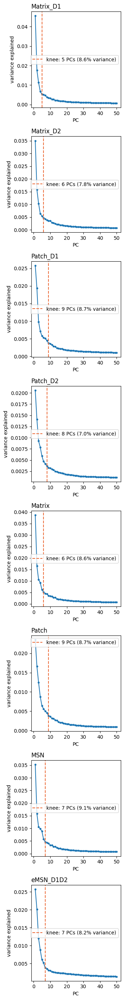

In [ ]:
fig, axes = plt.subplots(len(pcas), 1, figsize=(8, 3.5 * len(pcas)))
for ax, (group, pca) in zip(axes, pcas.items()):
    evr = pca.uns["variance_ratio"]
    knee = reference_pca.knee_point(evr)
    ax.plot(np.arange(1, len(evr) + 1), evr, "o-", ms=3)
    ax.axvline(knee, color="#eb6834", ls="--", label=f"knee: {knee} PCs ({evr[:knee].sum():.1%} variance)")
    ax.set_xlabel("PC")
    ax.set_ylabel("variance explained")
    ax.set_title(group, loc="left")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/scree.png", dpi=150)
plt.show()

### Top genes of each PC
Sign = sign of the loading: `+` genes are high in cells with a high score.

In [5]:
MIN_SPECIFICITY = 0.5    # "specific" gene: at least this fraction of its squared loading (over the plotted PCs) is on that PC


In [6]:
for group, pca in pcas.items():
    pcs = [f"PC_{i + 1}" for i in range(N_PCS_TO_PLOT)]
    loadings = pd.DataFrame(pca.varm["PCs"][:, :N_PCS_TO_PLOT], index=pca.var_names, columns=pcs)
    loadings = loadings[pca.var["highly_variable"].values]           # only HVGs have a loading

    # share of each gene's squared loading (over the plotted PCs) that is on each PC
    specificity = loadings ** 2 / (loadings ** 2).sum(axis=1).values[:, None]

    table = {}
    for pc in pcs:
        l = loadings[pc].sort_values()
        up = l.index[::-1][:N_TOP_GENES]
        down = l.index[:N_TOP_GENES]
        specific = l[specificity[pc] >= MIN_SPECIFICITY]
        specific = specific.abs().sort_values(ascending=False).index[:N_TOP_GENES]

        table[(pc, "up")] = pd.Series([f"{g} {l[g]:.3f}" for g in up])
        table[(pc, "down")] = pd.Series([f"{g} {l[g]:.3f}" for g in down])
        table[(pc, "specific")] = pd.Series([f"{g} {'+' if l[g] > 0 else '-'} ({specificity.loc[g, pc]:.0%})" for g in specific])

    print(group)
    with pd.option_context("display.max_columns", None, "display.max_rows", None,
                           "display.width", None, "display.max_colwidth", None):
        display(pd.DataFrame(table).fillna(""))




Matrix_D1


PC_1                                                     PC_2  \
                up                    down         specific              up   
0      PEG10 0.068          ZNF385B -0.064    PEG10 + (50%)   PPP1R1B 0.074   
1   HSP90AB1 0.065            OPCML -0.063    NORAD + (52%)      TAC1 0.072   
2      CALM1 0.064            PLCB1 -0.062    PEA15 + (63%)    ARPP19 0.071   
3      CTXN1 0.064            ROBO2 -0.056    CALM3 + (51%)      HPCA 0.069   
4      NORAD 0.063          SLC24A2 -0.055    VAMP2 + (54%)    PDE10A 0.065   
5       SCG2 0.063  ENSG00000286685 -0.055    PLCB1 - (53%)    SPOCK1 0.063   
6      PEA15 0.063        VLDLR-AS1 -0.055   PCSK1N + (53%)  IVNS1ABP 0.063   
7      CALM3 0.062           PDE10A -0.055  ATP6V0C + (51%)   ZNF385B 0.060   
8      VAMP2 0.062          STXBP5L -0.054     EIF1 + (56%)     GPR88 0.059   
9      VSNL1 0.061            KCND2 -0.053   ATP1B1 + (73%)     CALM1 0.059   
10    PCSK1N 0.061          COL25A1 -0.051     THRA + (52%)   PLEKHA7 0.058   
11   ATP6V0C 0.060            PTPRM -0.050    ACTG1 + (56%)    TALAM1 0.058   
12      NNAT 0.059           TESPA1 -0.050    ITM2C + (52%)    STXBP6 0.057   
13      EIF1 0.059           SPOCK1 -0.049     PSAP + (50%)    GPRIN3 0.055   
14     GAPDH 0.059              NTM -0.048     PRNP + (55%)      ACTB 0.055   
15    ATP1B1 0.059          PLEKHA7 -0.047     BEX3 + (56%)   PPP1R1A 0.052   
16      THY1 0.059             GRM8 -0.046   RHBDD2 + (55%)      THY1 0.052   
17      THRA 0.059            CHRM3 -0.045    SYT11 + (52%)   CAMK2N1 0.052   
18     ACTG1 0.059            APPAT -0.045  SERINC1 + (60%)      PSAP 0.051   
19     ITM2C 0.058          SYNDIG1 -0.045      FTL + (50%)     CHRM3 0.051   

                                                                      PC_3  \
                      down                 specific                     up   
0              HCN1 -0.068          PPP1R1B + (55%)           MT-CO3 0.124   
1           ARHGAP6 -0.064             TAC1 + (56%)           MT-CO2 0.124   
2             GRIA4 -0.063           ARPP19 + (51%)          MT-ATP8 0.124   
3             TIAM1 -0.060             HPCA + (55%)           MT-ND2 0.123   
4             PRKG1 -0.056          ARHGAP6 - (51%)           MT-ND1 0.123   
5            ATP2B4 -0.053          PPP1R1A + (55%)           MT-CYB 0.122   
6            PTPN13 -0.053           CFAP54 - (52%)          MT-ATP6 0.121   
7            DNAH14 -0.052             XACT - (54%)          MT-ND4L 0.120   
8   ENSG00000274422 -0.052             UPP2 - (51%)           MT-ND4 0.120   
9          KIAA2012 -0.051            ZMAT2 + (51%)           MT-ND3 0.119   
10           TMEFF2 -0.051        LINC01473 - (52%)           MT-CO1 0.113   
11            ZNF83 -0.050             RFX2 - (65%)           MT-ND5 0.112   
12          PRKAR2A -0.050              AK7 - (62%)             DHFR 0.110   
13             ANO4 -0.050           LRRIQ1 - (55%)  ENSG00000289901 0.106   
14  ENSG00000289899 -0.049            ABCC4 - (69%)            APPAT 0.084   
15        LINC00342 -0.049  ENSG00000237773 - (57%)             XIST 0.082   
16          SLC24A4 -0.049        LINC02144 - (56%)             BCOR 0.077   
17              GDA -0.048             CD36 - (52%)           MT-ND6 0.076   
18          GALNTL6 -0.048  ENSG00000257322 - (58%)        LINC00342 0.075   
19            CDH12 -0.048                                 LINC00632 0.072   

                                                                      PC_4  \
                      down                 specific                     up   
0             TRPS1 -0.078           MT-CO3 + (67%)  ENSG00000228566 0.110   
1            TTTY14 -0.077           MT-CO2 + (70%)          ZNF385D 0.100   
2            NLGN4Y -0.075          MT-ATP8 + (72%)             UTRN 0.096   
3            TALAM1 -0.071           MT-ND2 + (68%)         EPB41L4A 0.091   
4             CADM1 -0.068           MT-ND1 + (70%)            MCTP2 0.090   
5           

Matrix_D2


PC_1                                            \
                       up             down                 specific   
0           ZNF385B 0.082     PEG10 -0.071          ZNF385B + (73%)   
1             PLCB1 0.078     VSNL1 -0.068            PLCB1 + (77%)   
2             OPCML 0.076       GDA -0.068            OPCML + (53%)   
3            PDE10A 0.073   ARHGAP6 -0.067           PDE10A + (52%)   
4               MME 0.073     P2RY1 -0.066              MME + (58%)   
5             CHRM3 0.073     PRKG1 -0.065            CHRM3 + (56%)   
6           SLC24A2 0.070     GRIA4 -0.064          SLC24A2 + (51%)   
7   ENSG00000286685 0.067     PEA15 -0.064            VSNL1 - (52%)   
8         VLDLR-AS1 0.065     ZNF83 -0.063          ARHGAP6 - (57%)   
9             ROBO2 0.061      NNAT -0.061  ENSG00000286685 + (56%)   
10           TESPA1 0.061  HSP90AB1 -0.060            P2RY1 - (56%)   
11           SPOCK1 0.061    ATP2B4 -0.060            PEA15 - (50%)   
12            ERBB4 0.060     CREG2 -0.059            ROBO2 + (71%)   
13           GPRIN3 0.060      SCG2 -0.059           GABRA5 - (68%)   
14          PLEKHA7 0.059      HCN1 -0.059            LAMP5 - (55%)   
15              NTM 0.059    PCSK1N -0.058            KCTD4 - (70%)   
16            MERTK 0.059     NORAD -0.058           SFT2D2 - (60%)   
17          STXBP5L 0.058     OPRM1 -0.058           PGM2L1 - (64%)   
18            SAMD5 0.058     CTXN1 -0.058            PTPRT + (55%)   
19          COL25A1 0.057      THRA -0.057             RADX - (63%)   

             PC_2                                                   \
               up                    down                 specific   
0    ARPP19 0.091        LINC00342 -0.081           ARPP19 + (63%)   
1    TALAM1 0.085  ENSG00000274422 -0.078           TALAM1 + (63%)   
2   PPP1R1B 0.084          BMS1P14 -0.075          PPP1R1B + (54%)   
3     CALM1 0.080            APPAT -0.075            CALM1 + (50%)   
4     GPR88 0.075        ANKRD30BL -0.074            ACTG1 + (52%)   
5      PENK 0.071         CCDC144A -0.071          PPP1R1A + (68%)   
6    EEF1A1 0.070           MRPL41 -0.066            GPR52 + (54%)   
7      HPCA 0.069           ZNF883 -0.064          ZC3H12B - (51%)   
8     ACTG1 0.069  ENSG00000258410 -0.061             TEX9 - (64%)   
9     RPLP1 0.068          ZC3H12B -0.060           NEXMIF - (58%)   
10     PSAP 0.068          MT-ATP6 -0.059           ZNF345 - (62%)   
11     ACTB 0.068          FAM106A -0.057  ENSG00000286593 - (50%)   
12    NORAD 0.067           MT-ND3 -0.057         VASH1-DT - (52%)   
13     TPT1 0.066  ENSG00000291194 -0.055       RAB33B-AS1 - (50%)   
14     THY1 0.066        LINC01515 -0.053            RFLNA - (56%)   
15     RPS8 0.064        LINC01277 -0.052  ENSG00000273674 - (57%)   
16    CALM3 0.063          MT-ATP8 -0.052            TEKT1 - (54%)   
17   TOMM20 0.063  ENSG00000277701 -0.048           SNHG22 - (64%)   
18   RPL13A 0.062             TEX9 -0.048            MTMR8 - (65%)   
19     EIF1 0.062  ENSG00000289611 -0.048            ABCC4 - (52%)   

                     PC_3                                                   \
                       up                    down                 specific   
0            MT-CO2 0.131            USP9Y -0.096           MT-CO2 + (67%)   
1            MT-ND2 0.128              UTY -0.096           MT-ND2 + (63%)   
2            MT-CYB 0.125           TTTY14 -0.096           MT-CYB + (60%)   
3            MT-CO3 0.124           NLGN4Y -0.089           MT-CO3 + (57%)   
4            MT-CO1 0.123           LINGO2 -0.079           MT-CO1 + (59%)   
5           MT-ND4L 0.123  ENSG00000291034 -0.076          MT-ND4L + (59%)   
6            MT-ND1 0.122             GPC6 -0.068           MT-ND1 + (59%)   
7            MT-ND5 0.121            CADM1 -0.068           MT-ND5 + (62%)   
8            MT-ND4 0.117            FGF13 -0.059           MT-ND4 + (52%)   
9           MT-ATP8 0.114          GALNTL6 -0.057          

Patch_D1


PC_1                                            \
                       up             down                 specific   
0           ZNF385B 0.079      CRYM -0.073             CRYM - (68%)   
1             OPCML 0.079     VSNL1 -0.072            PEA15 - (61%)   
2            PDE10A 0.071      NNAT -0.072            CADM3 - (56%)   
3           COL25A1 0.064     PEA15 -0.071             DGKB + (53%)   
4              DGKB 0.063     CALM1 -0.070           GPR101 - (63%)   
5             PTPRM 0.062      THRA -0.067           SFT2D2 - (51%)   
6             ERBB4 0.057   ARHGAP6 -0.065           POU3F4 - (64%)   
7          KIAA1217 0.057     CADM3 -0.065            SSTR2 - (54%)   
8   ENSG00000287923 0.057  HSP90AB1 -0.065             PRLR - (54%)   
9            TESPA1 0.056     CTXN1 -0.065          CARHSP1 - (60%)   
10           SEMA6D 0.055     CALM3 -0.064             TMX4 - (58%)   
11  ENSG00000224363 0.055     PEG10 -0.064  ENSG00000257545 + (54%)   
12          PLEKHA7 0.055    PCSK1N -0.064              CCK - (51%)   
13             GRM3 0.053      PSAP -0.063             RTL9 - (50%)   
14           GPRIN3 0.053     NORAD -0.062            CRADD + (54%)   
15  ENSG00000286780 0.052     VAMP2 -0.062         CDK6-AS1 + (55%)   
16            WIPF3 0.052      EIF1 -0.062            CD109 - (53%)   
17            IQCA1 0.052       GDA -0.060          STEAP1B - (68%)   
18           GRIN2A 0.051    PGM2L1 -0.059  ENSG00000226965 + (69%)   
19             ETV6 0.050      BEX4 -0.059                            

             PC_2                                                   \
               up                    down                 specific   
0      TAC1 0.089            APPAT -0.074             TAC1 + (64%)   
1    TALAM1 0.074        LINC00342 -0.073           PMS2P4 - (51%)   
2      NRGN 0.074        ANKRD30BL -0.067            FOXG1 + (61%)   
3     CALM1 0.070  ENSG00000274422 -0.066            CCND2 + (52%)   
4      TPT1 0.064           PMS2P4 -0.066            DMGDH - (51%)   
5      ACTB 0.063          BMS1P14 -0.065  ENSG00000286593 - (69%)   
6     FOXG1 0.062           MRPL41 -0.063           PKD1L1 - (65%)   
7     RPLP1 0.062           ZNF883 -0.059           ZNF345 - (56%)   
8    HIVEP2 0.062  ENSG00000258410 -0.055  ENSG00000237596 + (58%)   
9      THY1 0.062  ENSG00000224905 -0.055  ENSG00000226471 - (53%)   
10    NORAD 0.061        LINC01277 -0.055  ENSG00000287704 + (54%)   
11   PDE10A 0.060              AK5 -0.055          DNAJC27 + (55%)   
12  CAMK2N1 0.060         CCDC144A -0.053            DRAIC - (66%)   
13    RPS23 0.059            ZNF83 -0.049  ENSG00000259255 + (53%)   
14  SELENOW 0.058  ENSG00000224363 -0.049     ANKRD34C-AS1 - (53%)   
15    VAMP2 0.058          ZC3H12B -0.049  ENSG00000259124 - (56%)   
16   EEF1A1 0.057          MT-ATP6 -0.048            TEKT1 - (53%)   
17    CALM3 0.057  ENSG00000280441 -0.048            MTMR8 - (58%)   
18  PPP1R1A 0.056           MT-ND3 -0.047            PPARA - (64%)   
19    RPLP2 0.056           CFAP54 -0.047  ENSG00000237773 - (57%)   

                     PC_3                                                   \
                       up                    down                 specific   
0            MT-CO2 0.128             GPC5 -0.080           MT-CO2 + (59%)   
1            MT-CYB 0.127  ENSG00000228566 -0.080           MT-CYB + (59%)   
2            MT-CO3 0.126          KHDRBS2 -0.077           MT-CO3 + (58%)   
3            MT-ND1 0.126              UTY -0.068           MT-ND1 + (58%)   
4           MT-ND4L 0.124            USP9Y -0.067          MT-ND4L + (60%)   
5            MT-CO1 0.123           NLGN4Y -0.066           MT-CO1 + (55%)   
6            MT-ND2 0.122            PCDH9 -0.064           MT-ND2 + (54%)   
7            MT-ND4 0.118        LINC01902 -0.063           MT-ND4 + (55%)   
8           MT-ATP8 0.118           TTTY14 -0.063          MT-ATP8 + (58%)   
9            MT-ND5 0.117            HTR2C -0.062          

... (6 outputs left out)

MSN


PC_1                                             PC_2  \
                       up             down         specific             up   
0           ZNF385B 0.076     PEG10 -0.073  ZNF385B + (59%)  PPP1R1B 0.081   
1             PLCB1 0.072     VSNL1 -0.069    PLCB1 + (58%)   TALAM1 0.075   
2             OPCML 0.071     PEA15 -0.067    PEA15 - (62%)     CNR1 0.072   
3            PDE10A 0.066  HSP90AB1 -0.067    KCTD4 - (68%)    CALM1 0.072   
4           SLC24A2 0.063     CALM1 -0.065    LAMP5 - (56%)     HPCA 0.071   
5         VLDLR-AS1 0.063     CTXN1 -0.065   GPR101 - (67%)    GPR88 0.066   
6   ENSG00000286685 0.063     NORAD -0.064   GABRA5 - (59%)     ACTB 0.064   
7           STXBP5L 0.059      SCG2 -0.064   PGRMC1 - (59%)   PDE10A 0.064   
8            SPOCK1 0.058    PCSK1N -0.064   SFT2D2 - (55%)   EEF1A1 0.063   
9             ROBO2 0.057     VAMP2 -0.063    YWHAH - (50%)     THY1 0.062   
10           TESPA1 0.057       GDA -0.063   PGM2L1 - (68%)    RPLP1 0.062   
11          COL25A1 0.055     CALM3 -0.063    RPL18 - (51%)     TPT1 0.061   
12          PLEKHA7 0.054      NNAT -0.063   MARCKS - (56%)    ACTG1 0.061   
13             GRM3 0.052   ARHGAP6 -0.062    MTCH1 - (57%)     PSAP 0.061   
14          SYNDIG1 0.050      THRA -0.061   NAP1L3 - (53%)  PPP1R1A 0.059   
15            ERBB4 0.048      EIF1 -0.061   TUBB2A - (52%)    NORAD 0.059   
16            PRKD1 0.048   ATP6V0C -0.061     ISCU - (51%)    CALM3 0.057   
17           CCDC39 0.048     GAPDH -0.060     RADX - (66%)  SELENOW 0.056   
18  ENSG00000287923 0.048    TOMM20 -0.060     BTG1 - (63%)     RPS8 0.056   
19            ADCY1 0.048     CREG2 -0.059  CARHSP1 - (56%)  CAMK2N1 0.056   

                                                                      PC_3  \
                      down                 specific                     up   
0         LINC00342 -0.070          PPP1R1B + (53%)           MT-CO2 0.108   
1   ENSG00000274422 -0.069          PPP1R1A + (63%)           MT-ND2 0.108   
2           BMS1P14 -0.067        GABARAPL2 + (50%)           MT-CYB 0.104   
3             APPAT -0.064             TEX9 - (66%)           MT-CO3 0.103   
4            MRPL41 -0.058            MYO16 - (57%)          MT-ND4L 0.103   
5          CCDC144A -0.058           ZNF345 - (56%)           MT-ND1 0.101   
6            ZNF883 -0.057             RFX4 + (54%)           MT-ND5 0.100   
7             GRIA4 -0.057           NEXMIF - (54%)           MT-ND4 0.099   
8   ENSG00000258410 -0.054             RFX2 - (57%)          MT-ATP8 0.098   
9           ARHGAP6 -0.053            TEKT1 - (59%)           MT-CO1 0.098   
10          MT-ATP6 -0.051  ENSG00000287272 - (67%)           MT-ND3 0.095   
11          ZC3H12B -0.051            ABCC4 - (69%)          MT-ATP6 0.093   
12           MT-ND3 -0.050            CD247 - (52%)             DHFR 0.091   
13             HCN1 -0.050  ENSG00000259124 - (53%)  ENSG00000289901 0.085   
14          SLC24A4 -0.050  ENSG00000237773 - (67%)             XIST 0.076   
15           ATP2B4 -0.049            MTMR8 - (67%)            SAMD5 0.069   
16          FAM106A -0.048         NEMP2-DT - (54%)           MT-ND6 0.069   
17           CFAP54 -0.048           RAB27A - (55%)            MAP1A 0.068   
18           PTPN13 -0.048        LINC02144 - (60%)           PHYHIP 0.067   
19             TEX9 -0.048  ENSG00000248636 - (61%)            CHRM3 0.066   

                                                                      PC_4  \
                      down                 specific                     up   
0              RELN -0.095           MT-CO2 + (50%)             DRD2 0.128   
1            LINGO2 -0.084           MT-ND2 + (51%)             FIG4 0.123   
2           GALNTL6 -0.077              NEB + (82%)             UTRN 0.116   
3              NRG1 -0.077        LINC01138 - (64%)             PENK 0.106   
4             LSAMP -0.077          NECTIN3 - (54%)            UNC5D 0.103   
5              GPC6 -0.076       RNF217-A

eMSN_D1D2


PC_1                                                       PC_2  \
                up                    down          specific               up   
0      CALM1 0.096        LINC00342 -0.075     CALM1 + (71%)    ZNF385B 0.089   
1       NRGN 0.093            APPAT -0.074      NRGN + (66%)      ESRRG 0.085   
2       TAC1 0.093             MMD2 -0.062      TAC1 + (70%)       CNR1 0.084   
3    CAMK2N1 0.088          CROCCP3 -0.058   CAMK2N1 + (68%)      GRIK1 0.078   
4       THY1 0.087  ENSG00000224363 -0.056      THY1 + (64%)       STAC 0.077   
5      VAMP2 0.085  ENSG00000274422 -0.056     VAMP2 + (68%)      EPHA5 0.069   
6    SELENOW 0.084          ZC3H12B -0.054   SELENOW + (73%)    SYNDIG1 0.068   
7    PPP1R1B 0.084           PMS2P4 -0.054   PPP1R1B + (57%)   ARHGAP10 0.068   
8   HSP90AB1 0.082         CCDC144A -0.053  HSP90AB1 + (52%)        WLS 0.068   
9    ATP6V0C 0.082          FAM106A -0.051   ATP6V0C + (60%)   KIAA1217 0.067   
10     SYT11 0.082           ZNF883 -0.050     SYT11 + (67%)       ELL2 0.065   
11      SCG2 0.081          STXBP5L -0.049      SCG2 + (52%)  LINC00472 0.065   
12     NORAD 0.080          MACROD2 -0.047     NORAD + (59%)      CNTN5 0.064   
13      ACTB 0.079           FAM27C -0.046      ACTB + (55%)     GRM5P1 0.059   
14     CALM3 0.079          BMS1P14 -0.046     CALM3 + (57%)  LINC01116 0.058   
15      BEX1 0.079  ENSG00000258410 -0.045      BEX1 + (71%)     LRRTM4 0.057   
16      EIF1 0.078        ANKRD30BL -0.045      EIF1 + (66%)       GLI3 0.056   
17     GAPDH 0.078        DIRC3-AS1 -0.042     ACTG1 + (70%)      KCNN2 0.054   
18     ACTG1 0.078        LINC01284 -0.041   SERINC1 + (63%)      WIPF3 0.054   
19   SERINC1 0.077  ENSG00000280441 -0.040      BEX3 + (66%)      ARAP2 0.053   

                                                            PC_3  \
                 down            specific                     up   
0        SYNPR -0.086     ZNF385B + (69%)             LDB2 0.110   
1        PDE4D -0.082       SYNPR - (52%)            PCDH9 0.093   
2        NDST3 -0.082       ESRRG + (61%)           TESPA1 0.091   
3        UNC5C -0.081        CNR1 + (50%)           ACVR1C 0.088   
4       CFAP47 -0.080       PDE4D - (54%)              NTM 0.085   
5   ST6GALNAC5 -0.079       NDST3 - (58%)            ZMAT4 0.080   
6       TMEM47 -0.077       UNC5C - (63%)          TPD52L1 0.079   
7        SEZ6L -0.076      CFAP47 - (78%)            ASTN2 0.079   
8        KCTD8 -0.076  ST6GALNAC5 - (61%)             PDYN 0.077   
9       BAIAP3 -0.072      TMEM47 - (83%)             XKR4 0.070   
10   ANKRD30BL -0.071       KCTD8 - (68%)           SRGAP1 0.070   
11       GAP43 -0.070      BAIAP3 - (58%)           SHISA9 0.069   
12   LINC01902 -0.070   ANKRD30BL - (54%)          CCDC196 0.068   
13     SPATS2L -0.070       GAP43 - (52%)            PLCL1 0.068   
14    TMEM132D -0.070   LINC01902 - (60%)             NRP2 0.067   
15      PLCXD3 -0.069       EPHA5 + (54%)  ENSG00000228566 0.064   
16      CAMK2D -0.068    ARHGAP10 + (53%)            PRKCH 0.064   
17       TENM3 -0.068   LINC00472 + (54%)          SLC24A2 0.063   
18   DIRC3-AS1 -0.068       CNTN5 + (62%)            PCDH7 0.060   
19       CADM1 -0.068       PEA15 - (61%)             SYT2 0.059   

                                                          PC_4  \
               down            specific                     up   
0        DCC -0.102        LDB2 + (63%)           MT-CO3 0.153   
1      DPP10 -0.096         DCC - (75%)           MT-CO2 0.153   
2     PDLIM5 -0.086       DPP10 - (66%)           MT-CYB 0.149   
3       EPS8 -0.082      TESPA1 + (88%)          MT-ND4L 0.148   
4      ROBO1 -0.082      ACVR1C + (59%)           MT-CO1 0.148   
5      LUZP2 -0.080      PDLIM5 - (67%)           MT-ND1 0.148   
6     PLCXD3 -0.079        EPS8 - (59%)           MT-ND2 0.143   
7       PRLR -0.079       ROBO1 - (64%)           MT-ND4 0.142   
8    SHROOM3 -0.079       ZMAT4 + (69%)           MT-ND5 0.142   
9      G

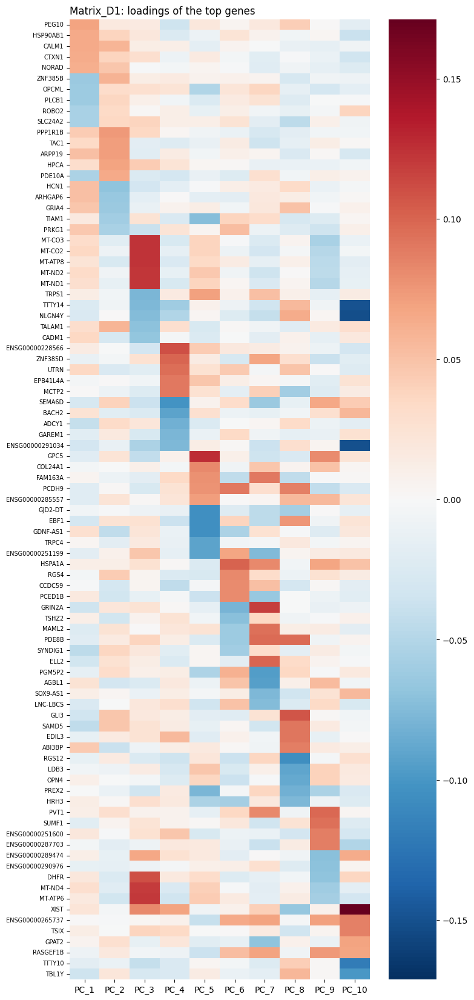

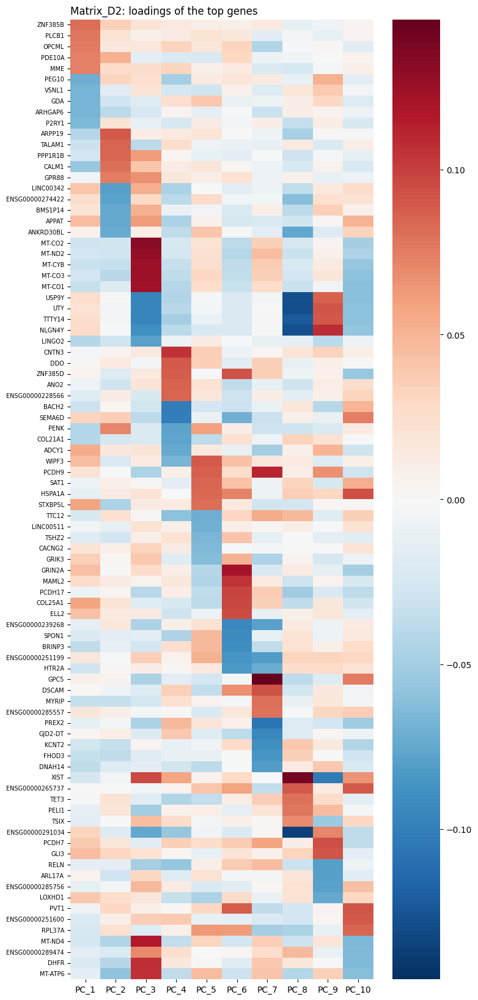

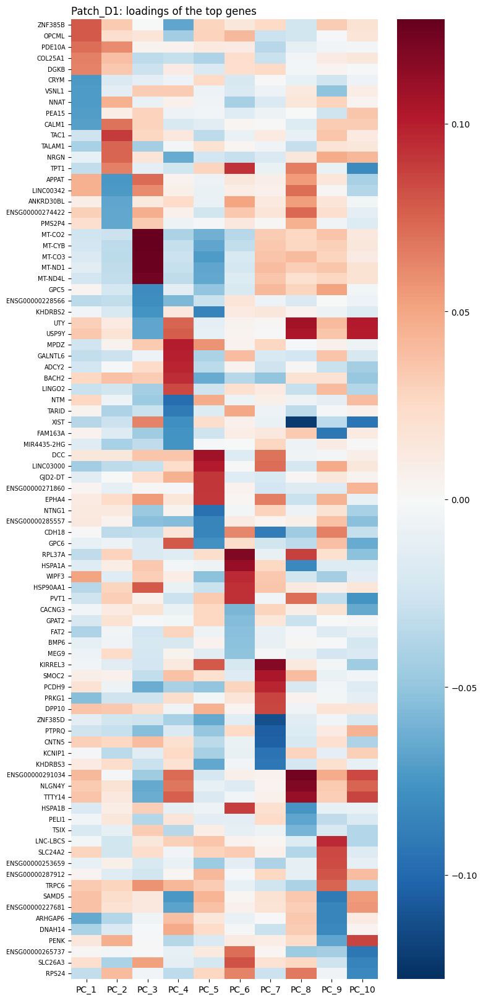

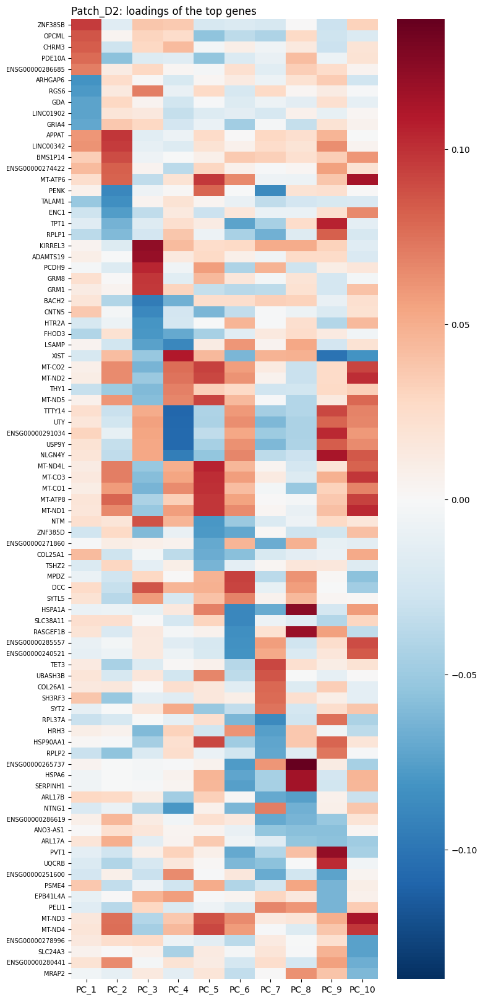

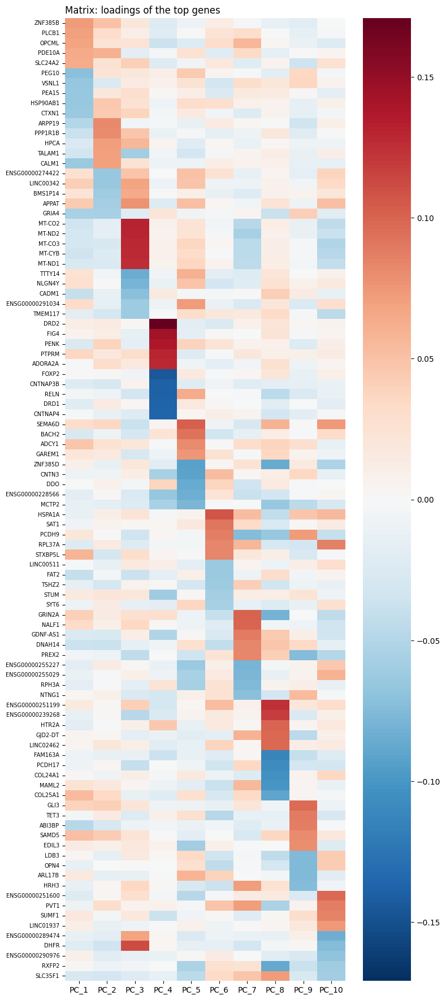

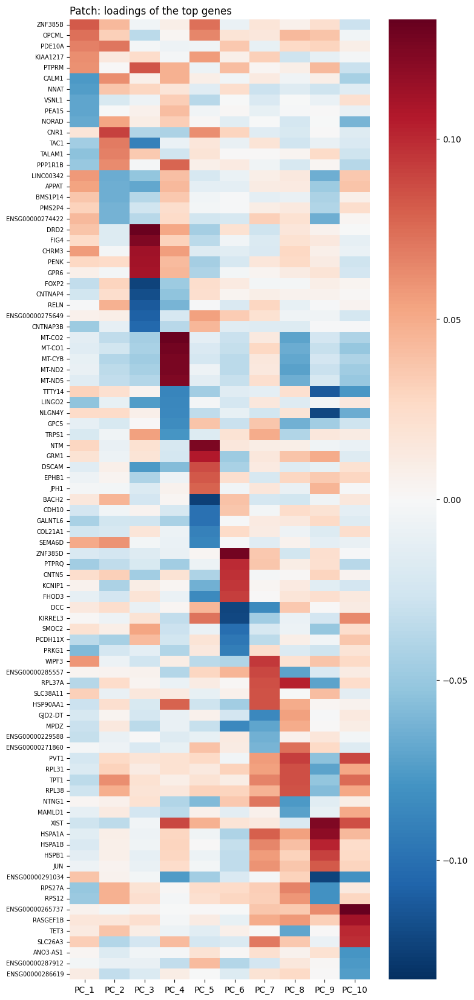

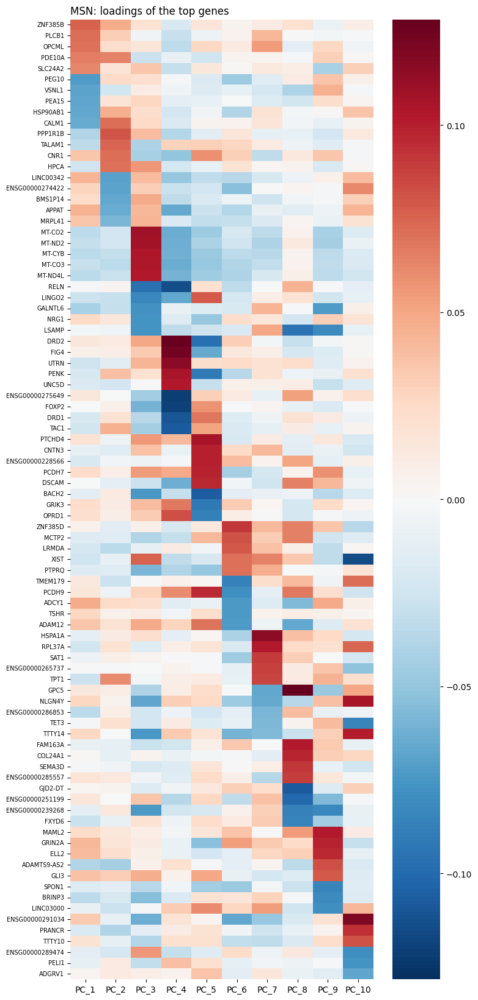

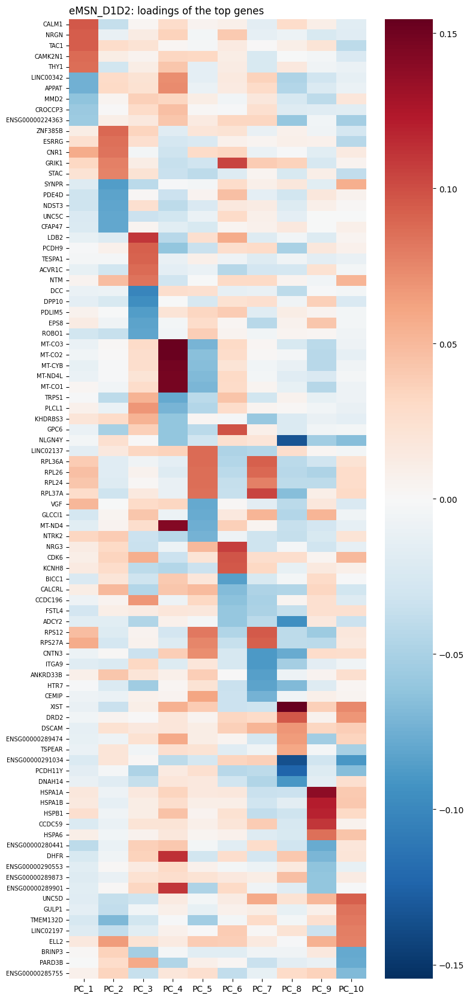

In [7]:
N_GENES_HEATMAP = 5    # per PC and direction

for group, pca in pcas.items():
    pcs = [f"PC_{i + 1}" for i in range(N_PCS_TO_PLOT)]
    loadings = pd.DataFrame(pca.varm["PCs"][:, :N_PCS_TO_PLOT], index=pca.var_names, columns=pcs)

    genes = []
    for pc in pcs:
        l = loadings[pc].sort_values()
        genes += [g for g in [*l.index[::-1][:N_GENES_HEATMAP], *l.index[:N_GENES_HEATMAP]] if g not in genes]

    lim = loadings.loc[genes].abs().max().max()
    plt.figure(figsize=(0.6 * len(pcs) + 2, 0.22 * len(genes) + 1))
    sns.heatmap(loadings.loc[genes], cmap="RdBu_r", vmin=-lim, vmax=lim, yticklabels=True)
    plt.title(f"{group}: loadings of the top genes", loc="left")
    plt.yticks(fontsize=7)
    plt.savefig(f"{SAVE_DIR}/{group}_top_gene_loadings.png", dpi=150, bbox_inches="tight")
    plt.show()


### What each PC follows: are QC pcs, spatial pcs, donor specific pcs, ...
* Spearman ρ with the dorsal–ventral position `r` and with `d`.
* η² (fraction of the PC's variance explained by the column) for donor, zone, region and BICAN file (D1/D2, Matrix/Patch).

High donor η² = a sample / technical axis. High `r` or zone = a spatial axis. High BICAN file = a cell identity axis.

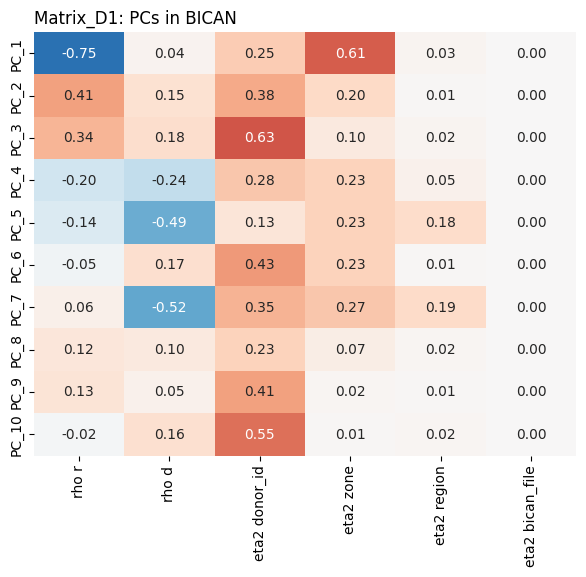

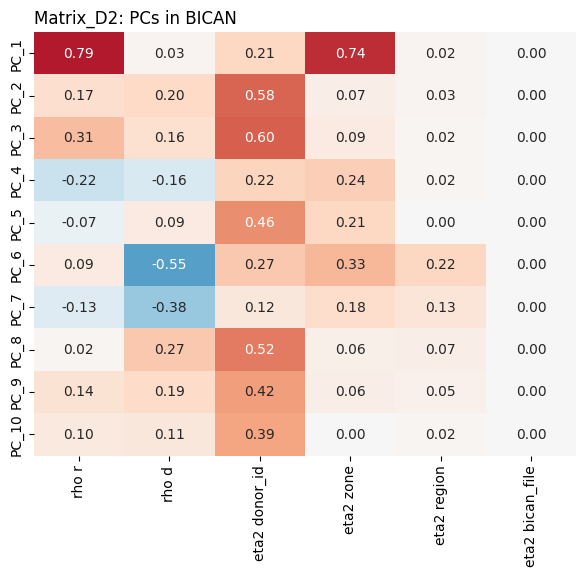

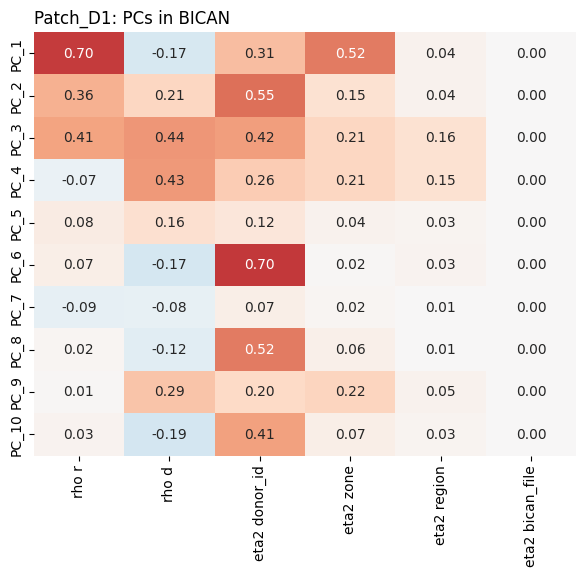

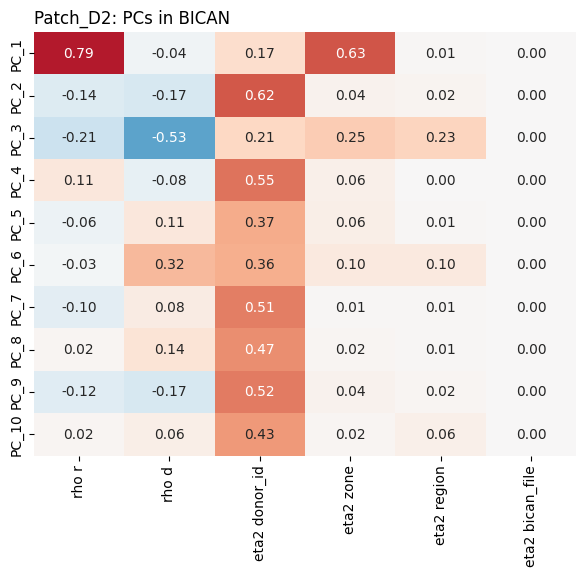

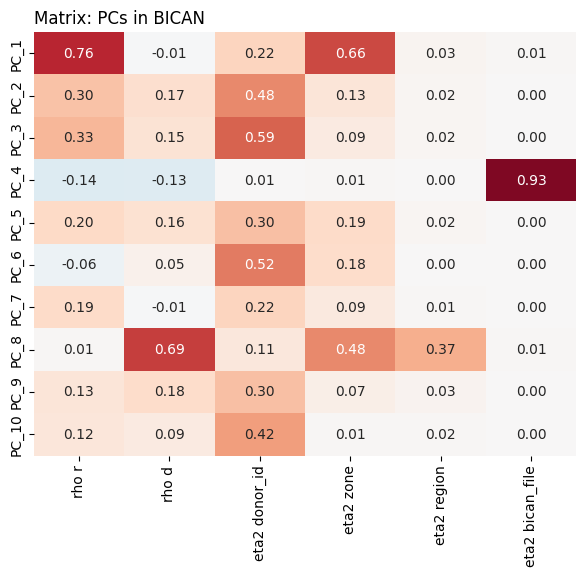

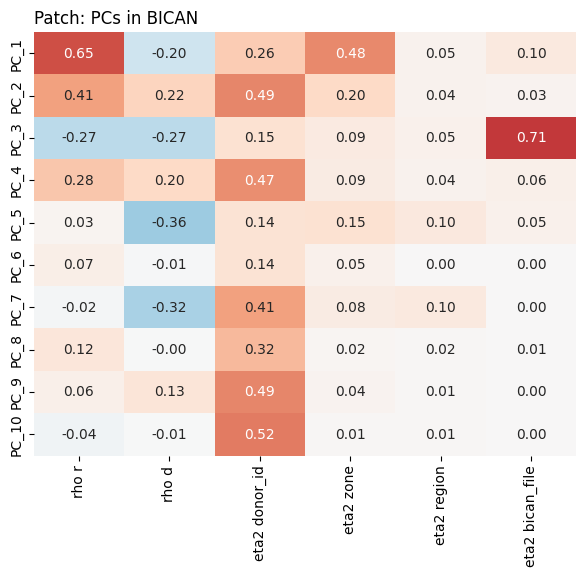

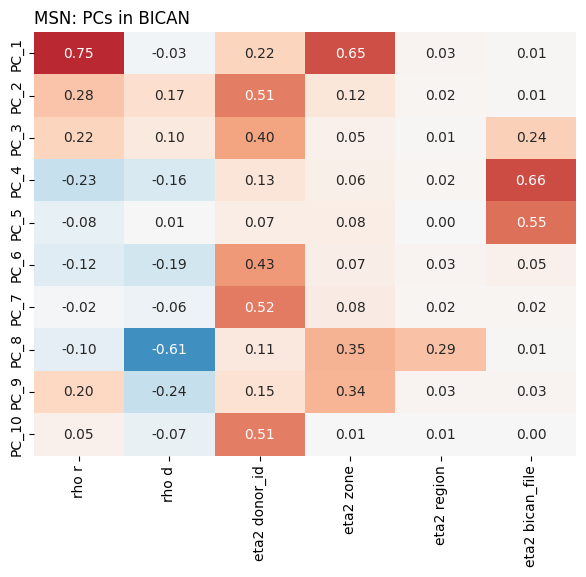

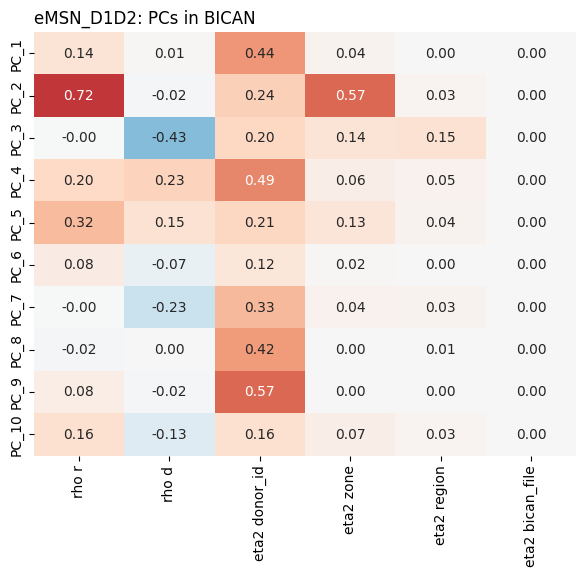

In [8]:
def eta2(values, groups):
    """Fraction of the variance of `values` explained by the categories in `groups`."""
    df = pd.DataFrame({"v": values, "g": groups})
    group_mean = df.groupby("g")["v"].transform("mean")
    return ((group_mean - df["v"].mean()) ** 2).sum() / ((df["v"] - df["v"].mean()) ** 2).sum()


for group, pca in pcas.items():
    o = pca.obs
    table = pd.DataFrame(index=[f"PC_{i + 1}" for i in range(N_PCS_TO_PLOT)])
    for i, pc in enumerate(table.index):
        score = pca.obsm["X_pca"][:, i]
        table.loc[pc, "rho r"] = pd.Series(score, index=o.index).corr(o["r"], method="spearman")
        table.loc[pc, "rho d"] = pd.Series(score, index=o.index).corr(o["d"], method="spearman")
        for col in ["donor_id", "zone", "region", "bican_file"]:
            table.loc[pc, f"eta2 {col}"] = eta2(score, o[col].astype(str).values)

    plt.figure(figsize=(7, 0.4 * len(table) + 1.5))
    sns.heatmap(table, vmin=-1, vmax=1, center=0, cmap="RdBu_r", annot=True, fmt=".2f", cbar=False)
    plt.title(f"{group}: PCs in BICAN", loc="left")
    plt.savefig(f"{SAVE_DIR}/{group}_pcs_vs_metadata.png", dpi=150, bbox_inches="tight")
    plt.show()

### PCs in space
One BICAN puck (`SPATIAL_DONOR`), grey = all cells of the puck. The first panel is the dorsal–ventral position `r`.

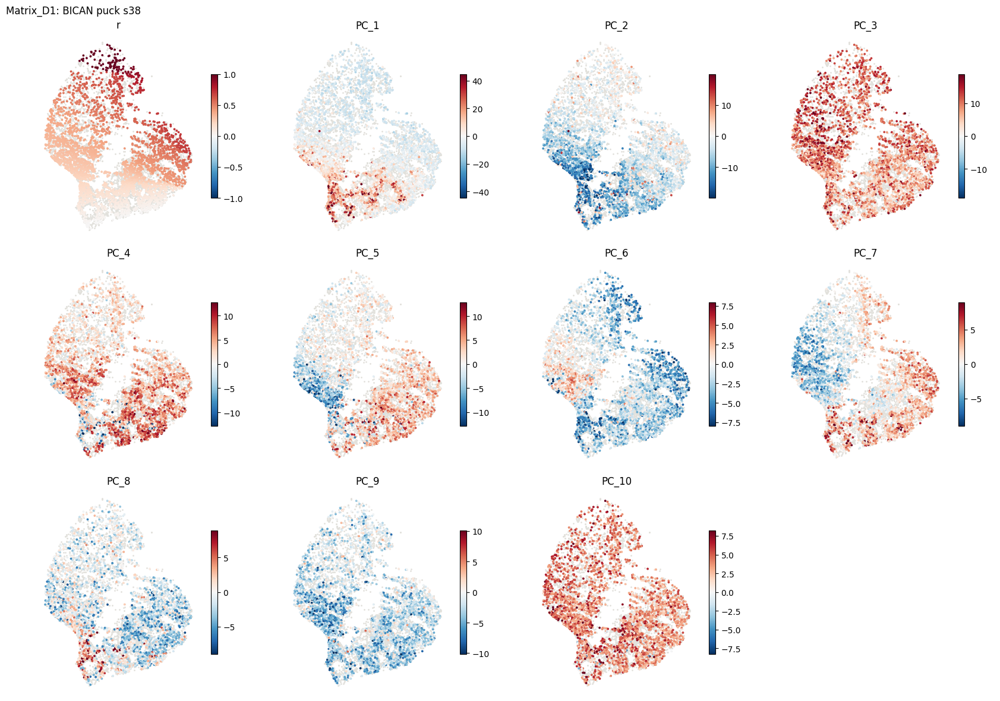

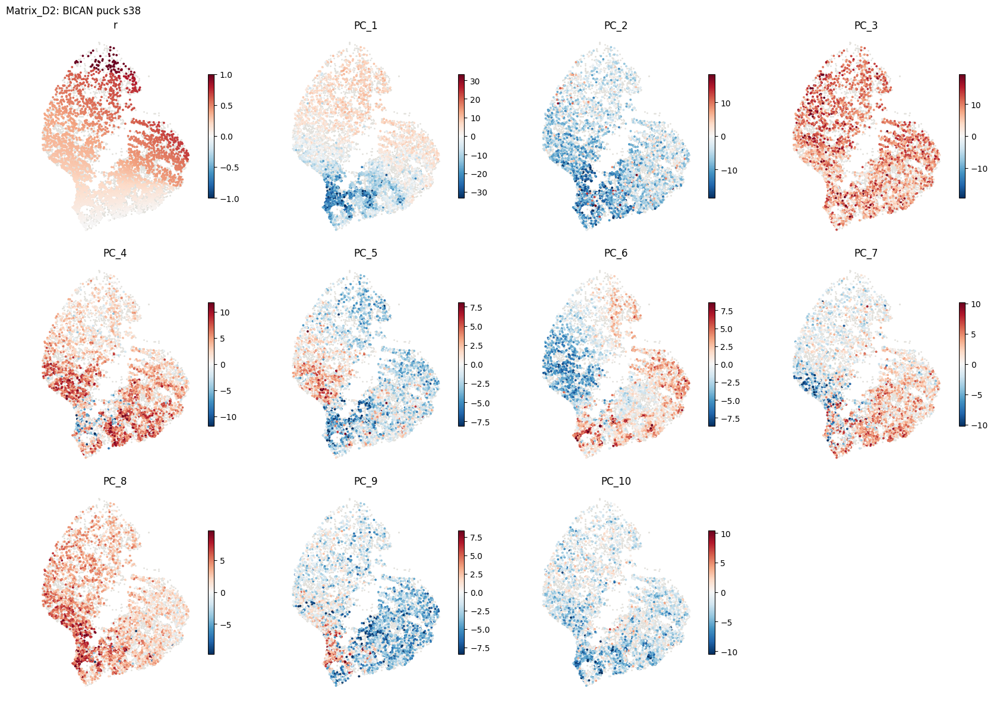

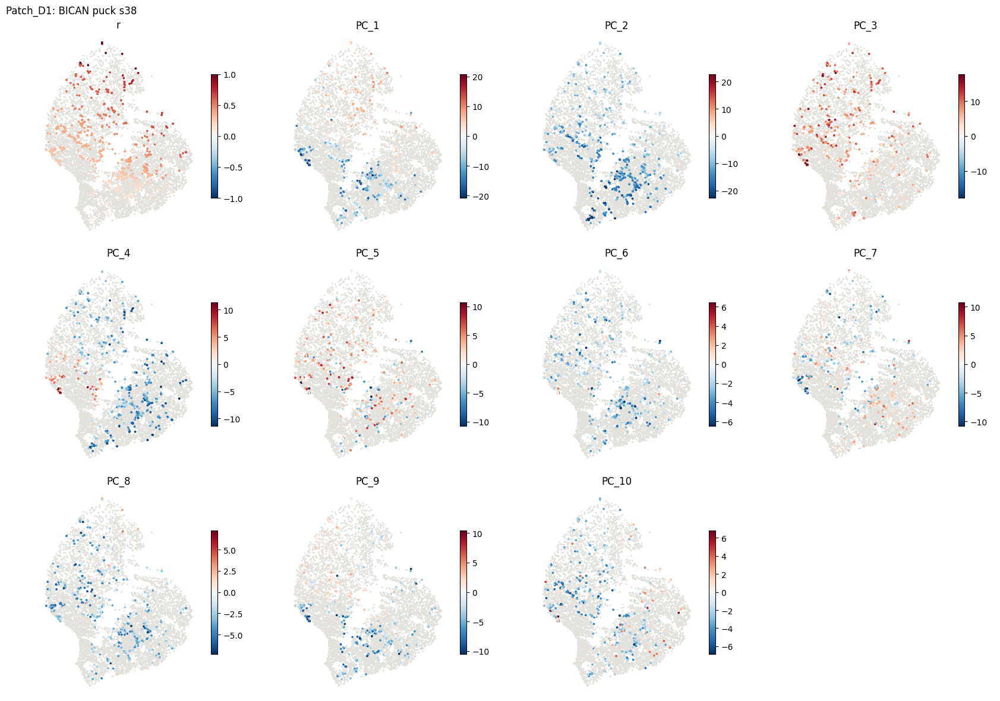

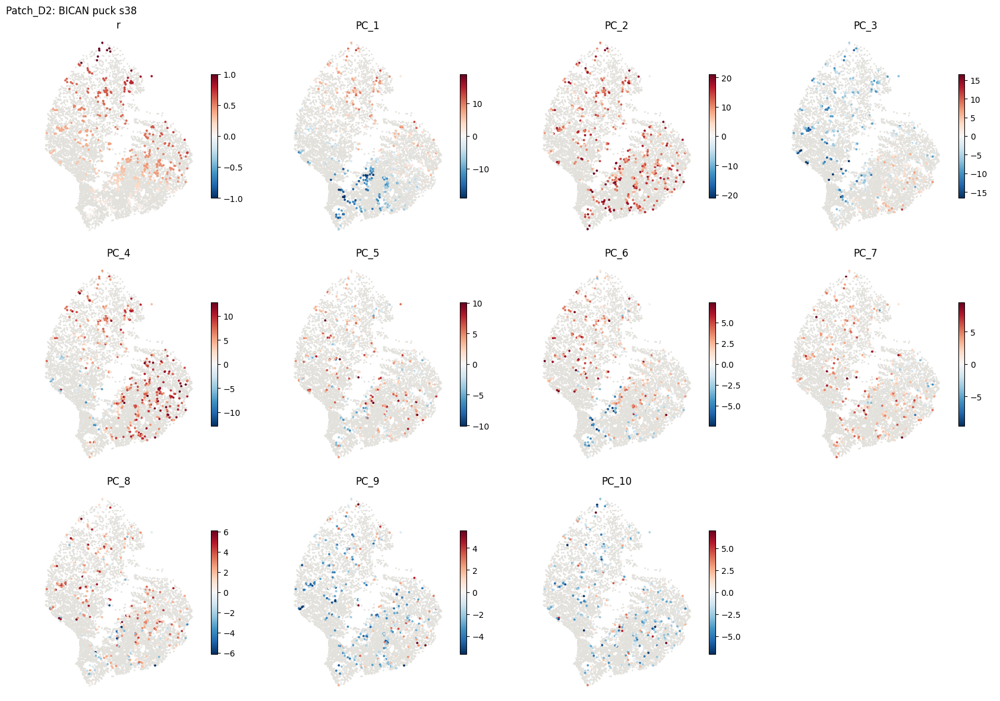

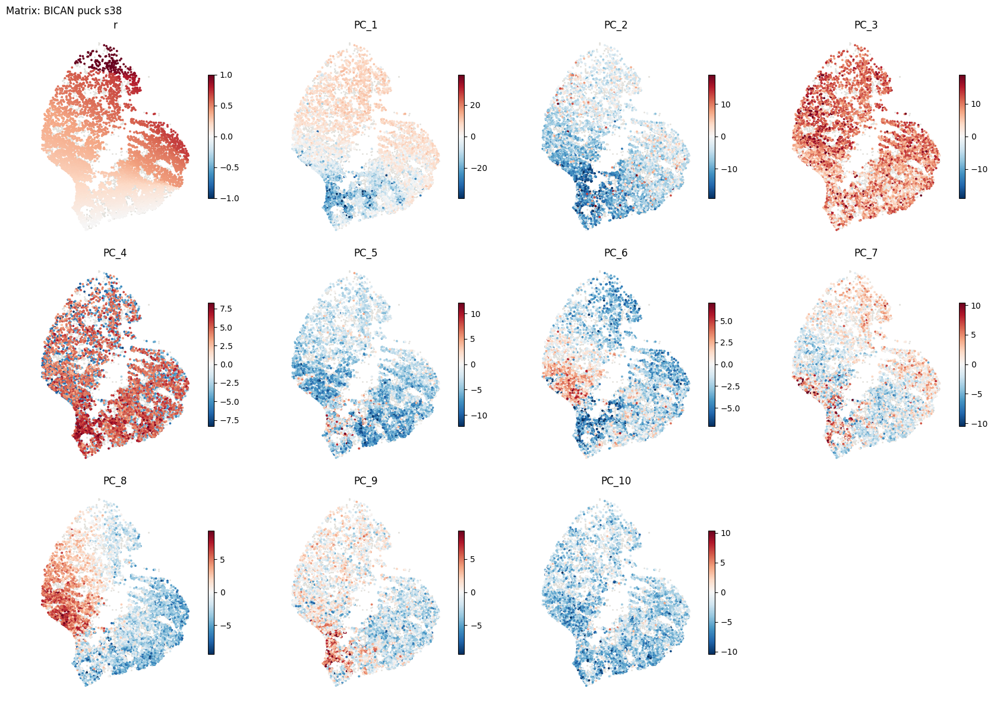

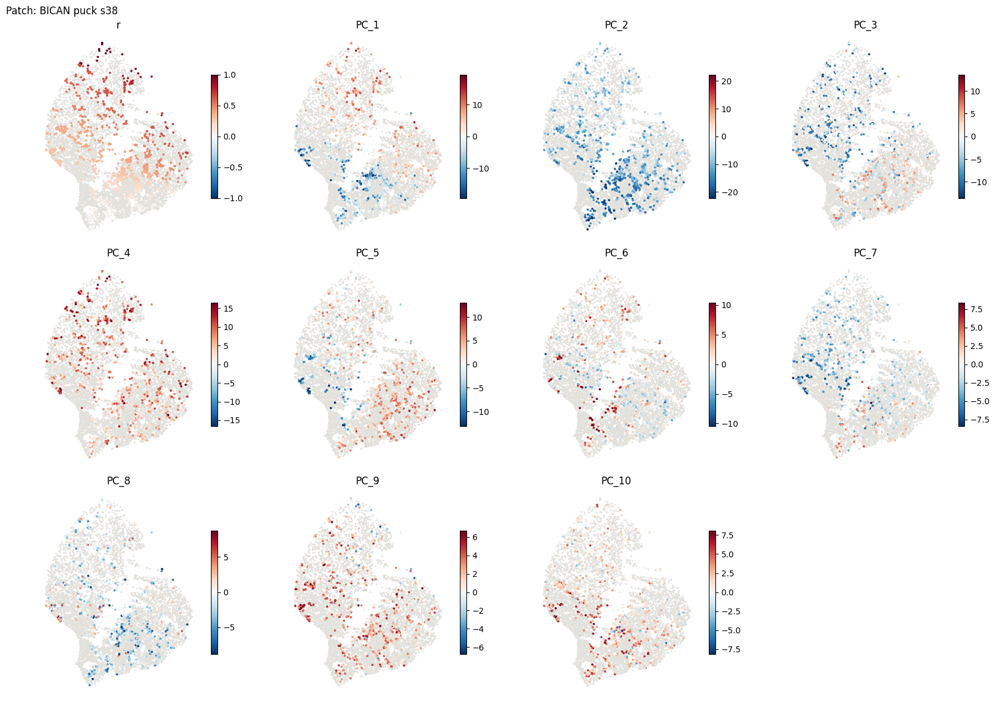

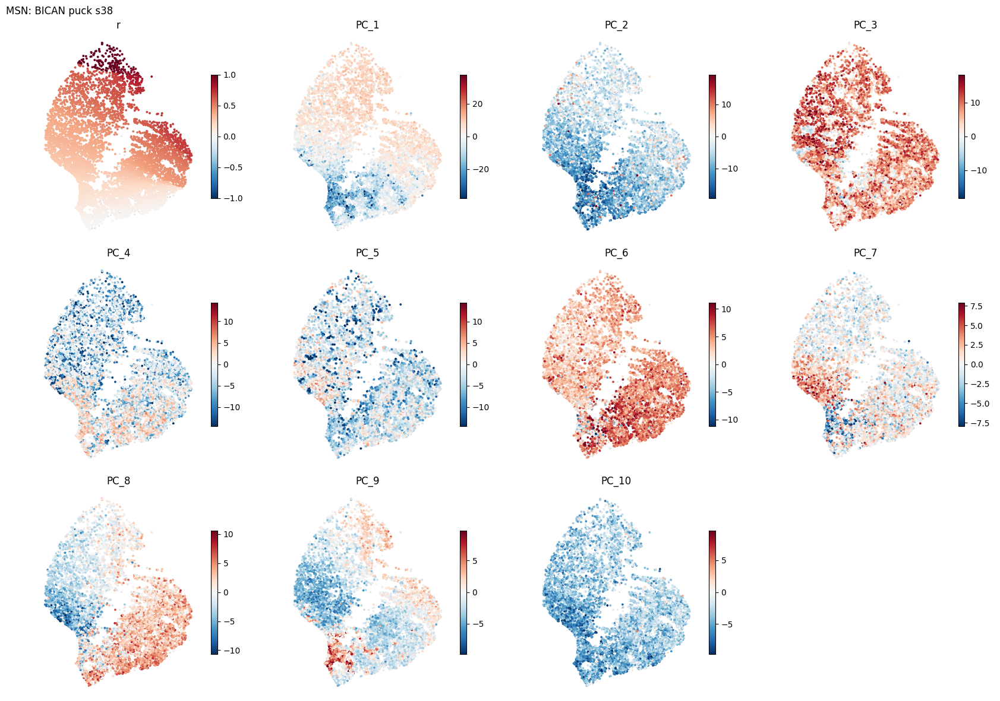

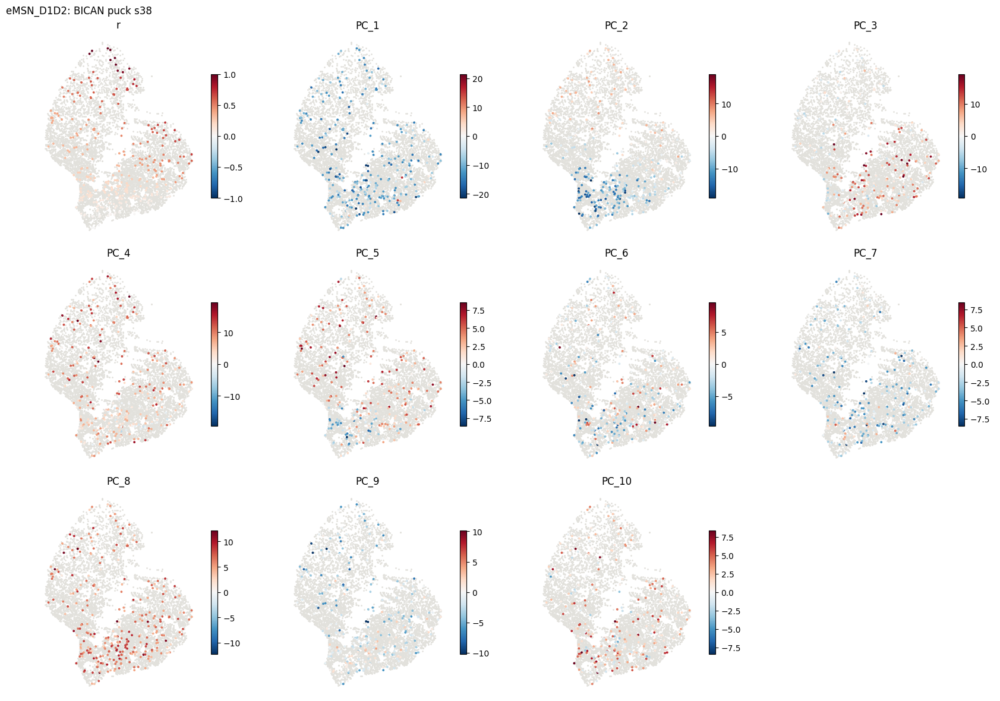

In [9]:
background = pd.read_csv(f"{SPLINES_DIR}/{SPATIAL_DONOR}_x_y_with_splines.csv")
for group, pca in pcas.items():
    in_puck = (pca.obs["donor_id"] == SPATIAL_DONOR).values
    puck = pca.obs[in_puck].copy()
    for i in range(N_PCS_TO_PLOT):
        puck[f"PC_{i + 1}"] = pca.obsm["X_pca"][in_puck, i]

    to_plot = ["r"] + [f"PC_{i + 1}" for i in range(N_PCS_TO_PLOT)]
    fig, axes = plt.subplots(3, 4, figsize=(17, 12))
    for ax, key in zip(axes.flat, to_plot):
        ax.scatter(background["x"], background["y"], s=1, c="#e2e1dc")
        lim = np.nanpercentile(np.abs(puck[key]), 99)
        points = ax.scatter(puck["x"], puck["y"], c=puck[key], s=3, cmap="RdBu_r", vmin=-lim, vmax=lim)
        plt.colorbar(points, ax=ax, shrink=0.6)
        ax.set_title(key)
        ax.set_aspect("equal")
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(f"{group}: BICAN puck {SPATIAL_DONOR}", x=0.01, ha="left")
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/{group}_pcs_in_space_{SPATIAL_DONOR}.png", dpi=150)
    plt.show()

### PC_1 vs PC_2

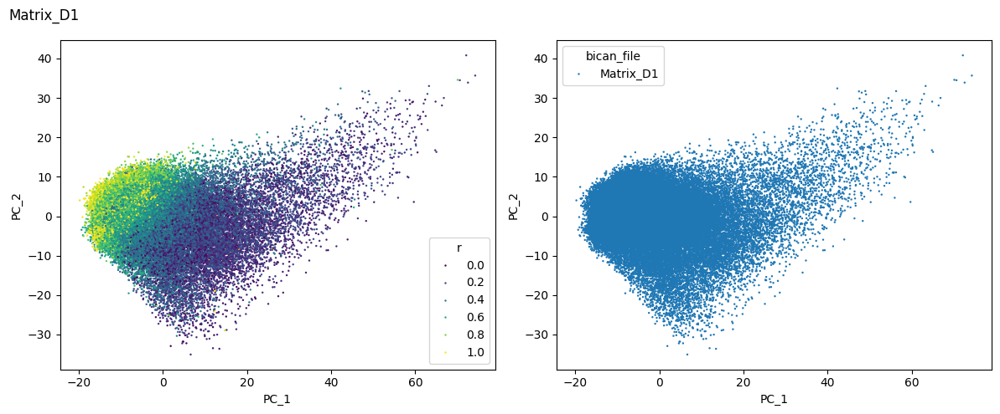

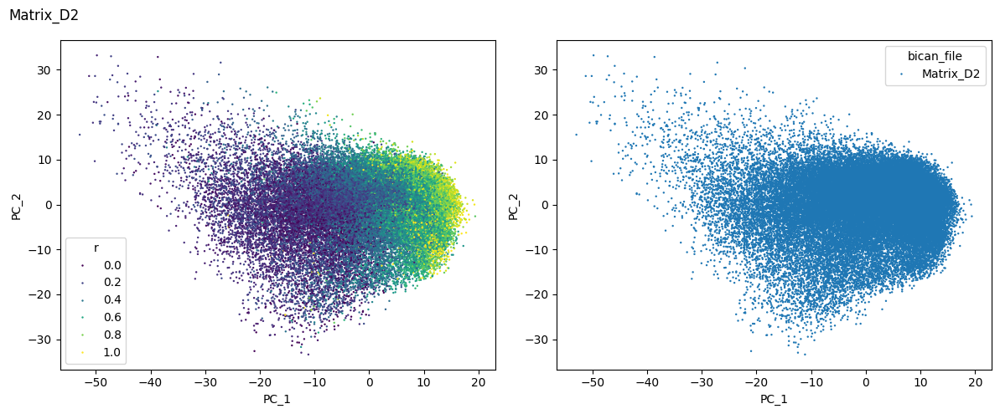

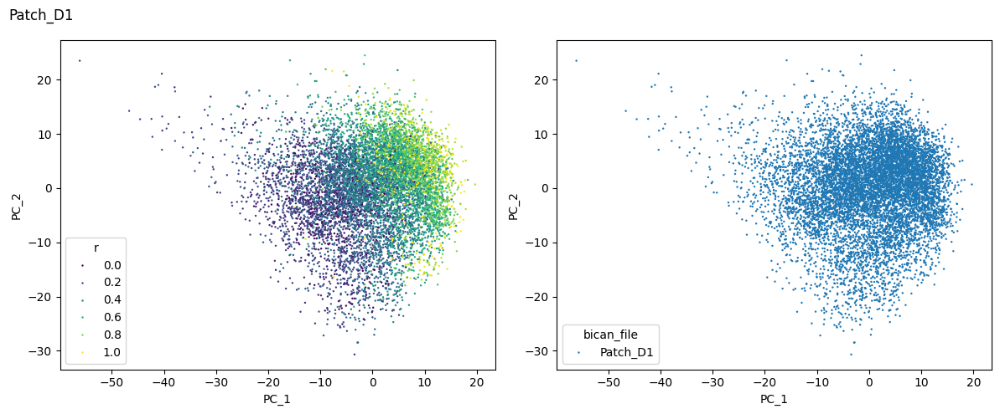

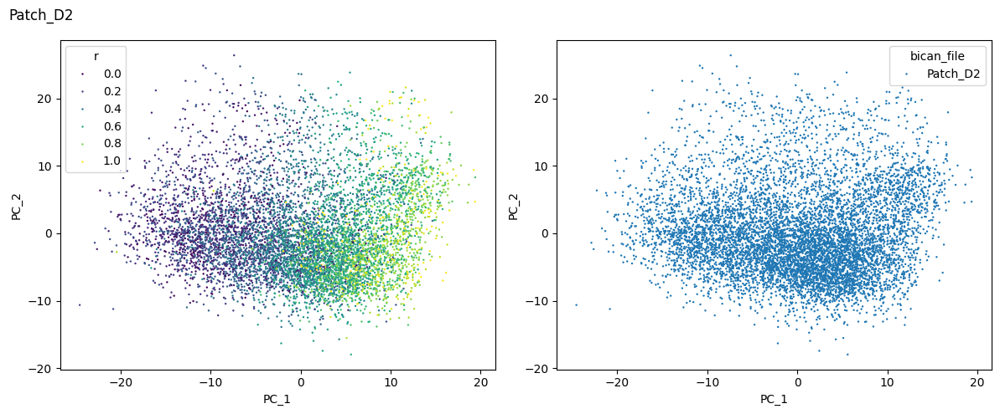

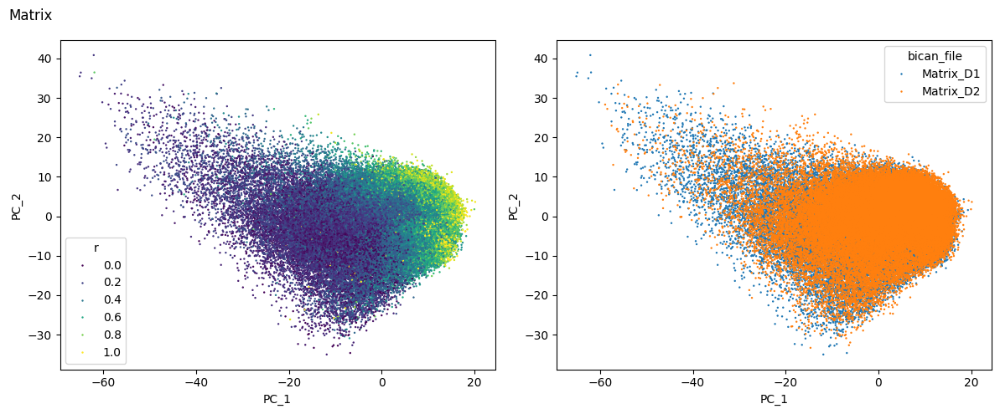

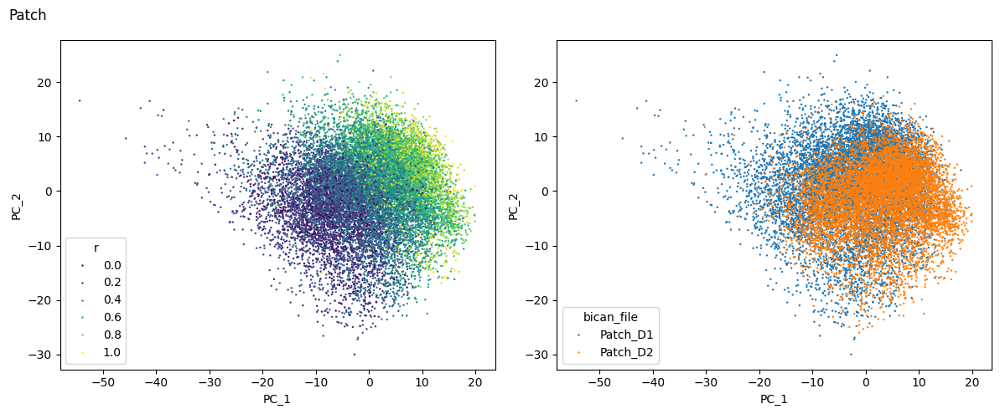

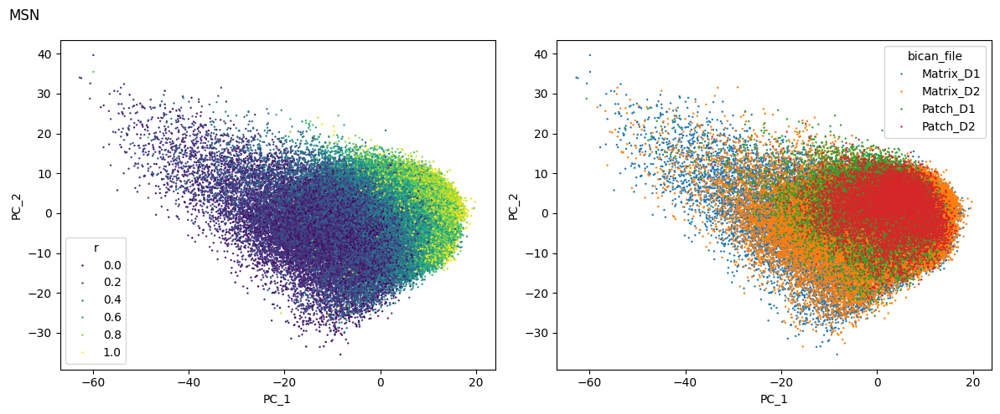

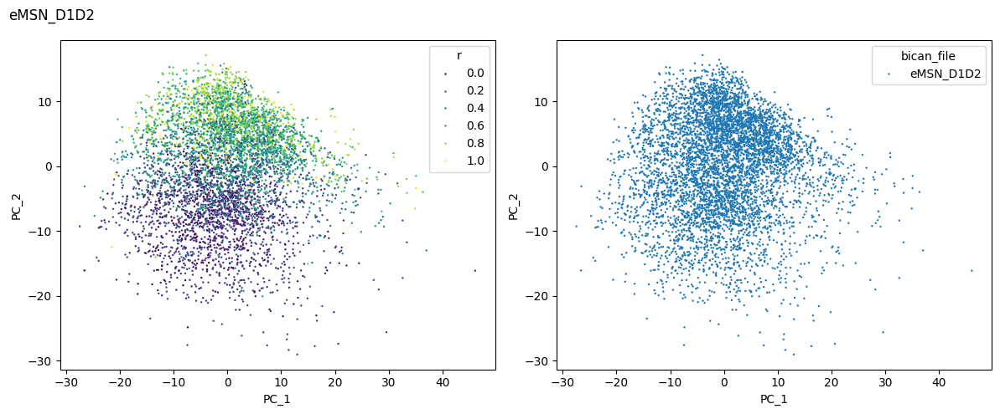

In [10]:
for group, pca in pcas.items():
    df = pca.obs.copy()
    df["PC_1"], df["PC_2"] = pca.obsm["X_pca"][:, 0], pca.obsm["X_pca"][:, 1]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.scatterplot(data=df, x="PC_1", y="PC_2", hue="r", palette="viridis", s=3, linewidth=0, ax=axes[0])
    sns.scatterplot(data=df, x="PC_1", y="PC_2", hue="bican_file", s=3, linewidth=0, ax=axes[1])
    fig.suptitle(group, x=0.01, ha="left")
    plt.tight_layout()
    plt.show()